In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import warnings
warnings.filterwarnings("ignore")

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

In [2]:
df = pd.read_csv(r'C:\Users\admin\OneDrive\Documents\UpGrad\NLP\spotify_dataset.csv')
df.head()

,Index,Highest Charting Position,Number of Times Charted,Week of Highest Charting,Song Name,Streams,Artist,Artist Followers,Song ID,Genre,...,Danceability,Energy,Loudness,Speechiness,Acousticness,Liveness,Tempo,Duration (ms),Valence,Chord
0,1,1,8,2021-07-23--2021-07-30,Beggin',"48,633,449",Måneskin,3377762,3Wrjm47oTz2sjIgck11l5e,"['indie rock italiano', 'italian pop']",...,0.714,0.8,-4.808,0.0504,0.127,0.359,134.002,211560,0.589,B
1,2,2,3,2021-07-23--2021-07-30,STAY (with Justin Bieber),"47,248,719",The Kid LAROI,2230022,5HCyWlXZPP0y6Gqq8TgA20,['australian hip hop'],...,0.591,0.764,-5.484,0.0483,0.0383,0.103,169.928,141806,0.478,C#/Db
2,3,1,11,2021-06-25--2021-07-02,good 4 u,"40,162,559",Olivia Rodrigo,6266514,4ZtFanR9U6ndgddUvNcjcG,['pop'],...,0.563,0.664,-5.044,0.154,0.335,0.0849,166.928,178147,0.688,A
3,4,3,5,2021-07-02--2021-07-09,Bad Habits,"37,799,456",Ed Sheeran,83293380,6PQ88X9TkUIAUIZJHW2upE,"['pop', 'uk pop']",...,0.808,0.897,-3.712,0.0348,0.0469,0.364,126.026,231041,0.591,B
4,5,5,1,2021-07-23--2021-07-30,INDUSTRY BABY (feat. Jack Harlow),"33,948,454",Lil Nas X,5473565,27NovPIUIRrOZoCHxABJwK,"['lgbtq+ hip hop', 'pop rap']",...,0.736,0.704,-7.409,0.0615,0.0203,0.0501,149.995,212000,0.894,D#/Eb


In [3]:
print("Shape:",df.shape)

Shape: (1556, 23)


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1556 entries, 0 to 1555
Data columns (total 23 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   Index                      1556 non-null   int64 
 1   Highest Charting Position  1556 non-null   int64 
 2   Number of Times Charted    1556 non-null   int64 
 3   Week of Highest Charting   1556 non-null   object
 4   Song Name                  1556 non-null   object
 5   Streams                    1556 non-null   object
 6   Artist                     1556 non-null   object
 7   Artist Followers           1556 non-null   object
 8   Song ID                    1556 non-null   object
 9   Genre                      1556 non-null   object
 10  Release Date               1556 non-null   object
 11  Weeks Charted              1556 non-null   object
 12  Popularity                 1556 non-null   object
 13  Danceability               1556 non-null   object
 14  Energy  

In [5]:
print(df.isnull().sum())

Index                        0
Highest Charting Position    0
Number of Times Charted      0
Week of Highest Charting     0
Song Name                    0
Streams                      0
Artist                       0
Artist Followers             0
Song ID                      0
Genre                        0
Release Date                 0
Weeks Charted                0
Popularity                   0
Danceability                 0
Energy                       0
Loudness                     0
Speechiness                  0
Acousticness                 0
Liveness                     0
Tempo                        0
Duration (ms)                0
Valence                      0
Chord                        0
dtype: int64


In [6]:
print("Duplicates:",df.duplicated().sum())

Duplicates: 0


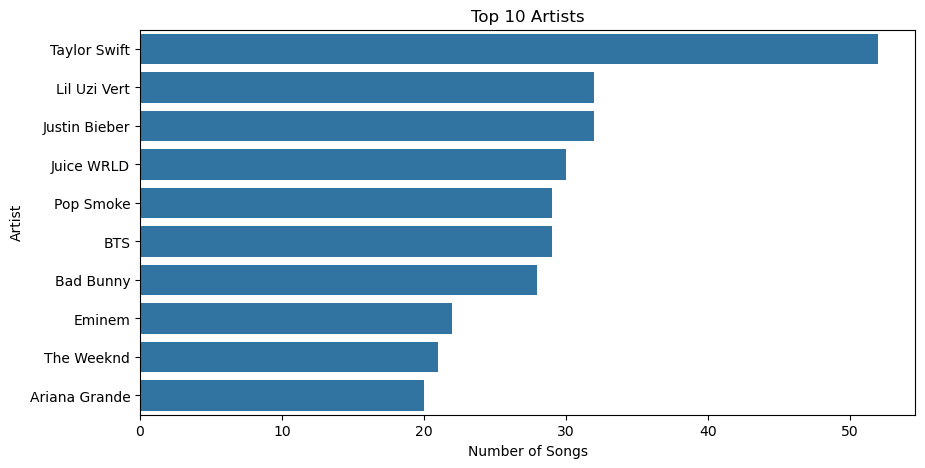

In [7]:
top_artists = df['Artist'].value_counts().head(10)

plt.figure(figsize=(10,5))
sns.barplot(x=top_artists.values,y=top_artists.index)

plt.title("Top 10 Artists")
plt.xlabel("Number of Songs")
plt.ylabel("Artist")
plt.show()

In [8]:
music = df[['Song Name','Artist','Genre','Chord']].copy()
music.head()

,Song Name,Artist,Genre,Chord
0,Beggin',Måneskin,"['indie rock italiano', 'italian pop']",B
1,STAY (with Justin Bieber),The Kid LAROI,['australian hip hop'],C#/Db
2,good 4 u,Olivia Rodrigo,['pop'],A
3,Bad Habits,Ed Sheeran,"['pop', 'uk pop']",B
4,INDUSTRY BABY (feat. Jack Harlow),Lil Nas X,"['lgbtq+ hip hop', 'pop rap']",D#/Eb


In [9]:
music = music.fillna('')

In [10]:
def clean_text(text):
    text = str(text)
    text = text.lower()
    text = re.sub(r'[^a-z0-9\s]','',text)
    text = re.sub(r'\s+','',text)
    return text.strip()

In [11]:
clean_text("Shape Of You - Ed Sheeran!")

'shapeofyouedsheeran'

In [12]:
for col in ['Song Name','Artist','Genre','Chord']:
    music[col] = music[col].apply(clean_text)

In [13]:
music['combined_features'] = (
    music['Song Name'] + ' ' +
    music['Artist'] + ' ' +
    music['Genre'] + ' ' +
    music['Chord']
)
music[['Song Name','Artist','Genre','Chord','combined_features']].head()

,Song Name,Artist,Genre,Chord,combined_features
0,beggin,mneskin,indierockitalianoitalianpop,b,beggin mneskin indierockitalianoitalianpop b
1,staywithjustinbieber,thekidlaroi,australianhiphop,cdb,staywithjustinbieber thekidlaroi australianhip...
2,good4u,oliviarodrigo,pop,a,good4u oliviarodrigo pop a
3,badhabits,edsheeran,popukpop,b,badhabits edsheeran popukpop b
4,industrybabyfeatjackharlow,lilnasx,lgbtqhiphoppoprap,deb,industrybabyfeatjackharlow lilnasx lgbtqhiphop...


In [14]:
tfidf = TfidfVectorizer(
    stop_words='english',
    ngram_range=(1,2)
)
tfidf_matrix = tfidf.fit_transform(
    music['combined_features']
)

print("TF-IDF Matrix Shape:",tfidf_matrix.shape)

TF-IDF Matrix Shape: (1556, 5263)


In [15]:
similarity = cosine_similarity(tfidf_matrix)
print("Similarity Matrix Shape:",similarity.shape)

Similarity Matrix Shape: (1556, 1556)


In [16]:
def recommend_songs(song_name,number_of_recommendations=10):

#find the song in the dataset
    matches = music[
        music['Song Name'].str.lower() == song_name.lower()
   ]

#Check whether the song exists 
    if matches.empty:
        return "Song not found in the datset."

#Get the index of the selected song    
    song_index = matches.index[0]

# Get similarity scores for the selected song
    scores = list(enumerate(similarity[song_index]))

# Sort songs by similarity in descending order
    sorted_scores = sorted(
        scores,
        key = lambda x:x[1],
        reverse = True
    )

# Remove the selected song itself
    sorted_scores = [
        item for item in sorted_scores
        if item[0] != song_index
    ]

# Select top recommendations
    top_songs = sorted_scores[:number_of_recommendations]

# Get recommended song indices
    song_indices = [item[0] for item in top_songs]

# Create recommendation output
    recommendations = music.loc[
        song_indices,
        ['Song Name','Artist','Genre']
        ].copy()
    

# Add similarity percentage
    recommendations['Similarity Score(%)'] = [
        round(score*100,2)
        for index,score in top_songs
    ]
    return recommendations.reset_index(drop = True)

In [17]:
recommend_songs("Beggin",10)

,Song Name,Artist,Genre,Similarity Score(%)
0,zittiebuoni,mneskin,indierockitalianoitalianpop,53.76
1,coraline,mneskin,indierockitalianoitalianpop,53.76
2,iwannabeyourslave,mneskin,indierockitalianoitalianpop,47.77
3,staywithjustinbieber,thekidlaroi,australianhiphop,0.00
4,good4u,oliviarodrigo,pop,0.00
5,badhabits,edsheeran,popukpop,0.00
6,industrybabyfeatjackharlow,lilnasx,lgbtqhiphoppoprap,0.00
7,monterocallmebyyourname,lilnasx,lgbtqhiphoppoprap,0.00
8,kissmemorefeatsza,dojacat,dancepoppop,0.00
9,tododeti,rauwalejandro,puertoricanpoptraplatino,0.00


In [18]:
recommend_songs("staywithjustinbieber",10)

,Song Name,Artist,Genre,Similarity Score(%)
0,withoutyou,thekidlaroi,australianhiphop,42.72
1,withoutyouwithmileycyrus,thekidlaroi,australianhiphop,42.72
2,sodone,thekidlaroi,australianhiphop,42.72
3,alwaysdo,thekidlaroi,australianhiphop,37.71
4,tragicfeatyoungboyneverbrokeagaininternetmoney,thekidlaroi,australianhiphop,37.71
5,gofeatjuicewrld,thekidlaroi,australianhiphop,37.68
6,tellmewhy,thekidlaroi,australianhiphop,37.68
7,notsoberfeatpologstunnagambino,thekidlaroi,,17.15
8,astronautintheocean,maskedwolf,australianhiphop,12.92
9,holdon,justinbieber,,3.58


In [19]:
recommend_songs("good4u", 10)

,Song Name,Artist,Genre,Similarity Score(%)
0,dejavu,oliviarodrigo,pop,44.91
1,favoritecrime,oliviarodrigo,pop,44.91
2,brutal,oliviarodrigo,pop,44.91
3,enoughforyou,oliviarodrigo,pop,44.91
4,1stepforward3stepsback,oliviarodrigo,pop,44.91
5,hopeurok,oliviarodrigo,pop,44.91
6,alliwantfromhighschoolmusicalthemusicaltheseries,oliviarodrigo,pop,44.91
7,driverslicense,oliviarodrigo,pop,39.30
8,jealousyjealousy,oliviarodrigo,pop,39.30
9,happier,oliviarodrigo,pop,39.30


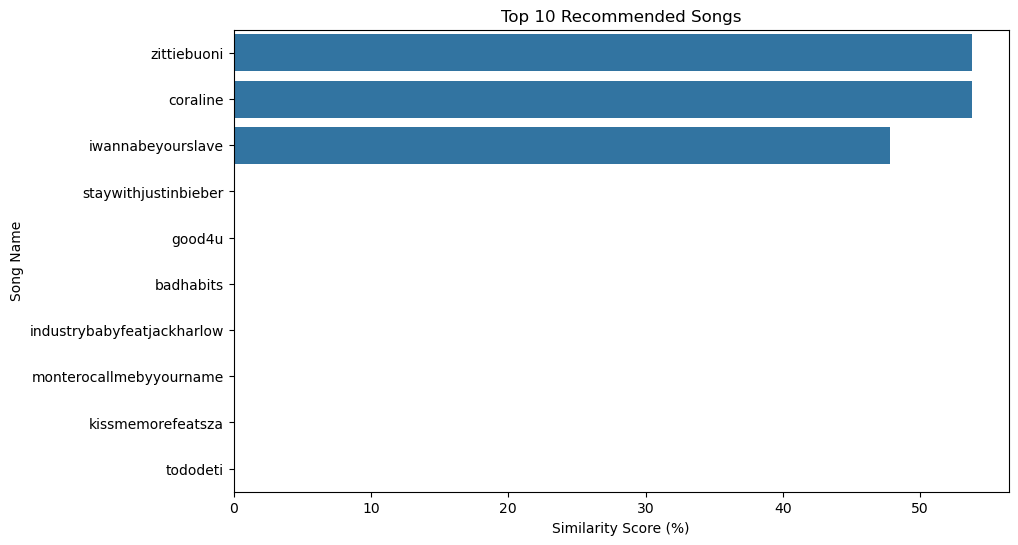

In [20]:
result = recommend_songs("Beggin",10)

if isinstance(result,pd.DataFrame):
    plt.figure(figsize=(10,6))

    sns.barplot(
        data = result,
        x = 'Similarity Score(%)',
        y = 'Song Name'
    )

    plt.title("Top 10 Recommended Songs")
    plt.xlabel("Similarity Score (%)")
    plt.ylabel("Song Name")
    plt.show()

# Spotify Music Recommendation System Using NLP

## 1. Introduction

The Spotify Music Recommendation System is a content-based recommendation project developed using Natural Language Processing (NLP) and Machine Learning techniques.

The main objective is to recommend songs based on their textual similarities, including song names, artists, genres, and musical information.

## 2. Problem Statement

Music streaming platforms contain thousands of songs. Finding songs similar to a user's preferred music can be difficult.

This project aims to solve this problem by developing an automated recommendation system that identifies and recommends similar songs based on their metadata.

## 3. Dataset Description

The project uses the Spotify dataset containing 1,556 records and 23 columns.

Important features include:
- Song Name
- Artist
- Genre
- Popularity
- Danceability
- Energy
- Tempo
- Chord

The dataset contains no missing values and no duplicate rows.

## 4. Objectives

- Understand and analyze Spotify music data.
- Perform data cleaning and preprocessing.
- Apply NLP techniques to textual features.
- Convert text into numerical representations using TF-IDF.
- Calculate similarity using cosine similarity.
- Recommend similar songs automatically.

## 5. Technologies Used

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn
- Natural Language Processing

## 6. Methodology

### Step 1: Data Collection
Loaded the Spotify dataset using Pandas.

### Step 2: Exploratory Data Analysis
Analyzed dataset dimensions, columns, missing values, duplicates, and artist distributions.

### Step 3: Data Preprocessing
Selected relevant text columns and cleaned the text by converting it into lowercase and removing unnecessary special characters.

### Step 4: Feature Engineering
Combined song name, artist, genre, and chord into a single textual feature.

### Step 5: TF-IDF Vectorization
Applied TF-IDF to transform textual information into numerical vectors.

### Step 6: Cosine Similarity
Calculated cosine similarity between songs to identify similar music.

### Step 7: Recommendation System
Developed a recommendation function that accepts a song name and returns the top 10 similar songs.

## 7. Algorithm Used

**TF-IDF:** Determines the importance of words in song metadata.

**Cosine Similarity:** Measures the similarity between two song vectors.

## 8. Expected Output

The system accepts a song name as input and generates a list of recommended songs containing:

- Song name
- Artist
- Genre
- Similarity percentage

## 9. Conclusion

The project successfully demonstrates how NLP techniques can be used to develop a content-based music recommendation system.

TF-IDF converts textual song information into numerical representations, while cosine similarity identifies songs with similar metadata.

This project demonstrates practical applications of Python, NLP, feature engineering, and machine learning in recommendation systems.

## 10. Future Scope

- Develop a hybrid recommendation system using NLP and audio features.
- Integrate Spotify API for real-time music information.
- Develop an interactive web application using Streamlit.
- Improve recommendations using user listening history.
- Implement collaborative filtering.


# *Deployment*

In [21]:
import pickle

#Store the existing model objects
model_data ={
    "music":music,
    "tfidf":tfidf,
    "tfidf_matrix":tfidf_matrix,
    "similarity":similarity
}

# Save everything into one pickle file
with open("spotify_recommender.pkl","wb") as file:
    pickle.dump(model_data,file)

print("Model saved successfully!")


Model saved successfully!


In [22]:
print(music.columns.tolist())
print(music.head())

['Song Name', 'Artist', 'Genre', 'Chord', 'combined_features']
                    Song Name         Artist                        Genre  \
0                      beggin        mneskin  indierockitalianoitalianpop   
1        staywithjustinbieber    thekidlaroi             australianhiphop   
2                      good4u  oliviarodrigo                          pop   
3                   badhabits      edsheeran                     popukpop   
4  industrybabyfeatjackharlow        lilnasx            lgbtqhiphoppoprap   

  Chord                                  combined_features  
0     b       beggin mneskin indierockitalianoitalianpop b  
1   cdb  staywithjustinbieber thekidlaroi australianhip...  
2     a                         good4u oliviarodrigo pop a  
3     b                     badhabits edsheeran popukpop b  
4   deb  industrybabyfeatjackharlow lilnasx lgbtqhiphop...  


In [23]:
%%writefile Spotify-Music-Recommendation-System.py

import streamlit as st
import os
import pickle
import pandas as pd

# ==========================================
# 1. PAGE CONFIGURATION
# ==========================================

st.set_page_config(
    page_title="Spotify Music Recommender",
    page_icon="🎵",
    layout="wide",
    initial_sidebar_state="expanded"
)


# ==========================================
# 2. CUSTOM CSS
# ==========================================

st.markdown("""
<style>

/* =====================================
   MAIN APPLICATION
===================================== */

.stApp {
    background: linear-gradient(135deg, #101820, #17232d);
    color: #ffffff;
}

header[data-testid="stHeader"] {
    background: transparent;
}

.block-container {
    padding-top: 2rem;
    padding-bottom: 3rem;
}


/* =====================================
   MAIN HEADINGS
===================================== */

.main-title {
    font-size: 38px;
    font-weight: 800;
    color: #1DB954 !important;
    margin-bottom: 5px;
}

.subtitle {
    color: #b3b3b3 !important;
    font-size: 16px;
}

.section-title {
    color: #1DB954 !important;
    font-size: 23px;
    font-weight: 700;
    margin-top: 20px;
}


/* =====================================
   SIDEBAR DESIGN
===================================== */

[data-testid="stSidebar"] {
    background-color: #101820;
}

[data-testid="stSidebar"] h1,
[data-testid="stSidebar"] h2,
[data-testid="stSidebar"] h3,
[data-testid="stSidebar"] h4,
[data-testid="stSidebar"] h5,
[data-testid="stSidebar"] h6 {
    color: #ffffff !important;
}

[data-testid="stSidebar"] p,
[data-testid="stSidebar"] span,
[data-testid="stSidebar"] label,
[data-testid="stSidebar"] li,
[data-testid="stSidebar"] strong {
    color: #ffffff !important;
}

[data-testid="stSidebar"] [data-testid="stCaption"] {
    color: #b3b3b3 !important;
}

[data-testid="stSidebar"] hr {
    border-color: #52616b !important;
}


/* =====================================
   SONG RECOMMENDATION CARDS
===================================== */

.song-card {
    background-color: #202e38;
    padding: 18px;
    border-radius: 12px;
    border: 1px solid #344550;
    margin-bottom: 12px;
}

.song-name {
    color: #ffffff !important;
    font-size: 20px;
    font-weight: 700;
}

.artist-name {
    color: #b3b3b3 !important;
    font-size: 15px;
    margin-top: 8px;
}

.genre-name {
    color: #1DB954 !important;
    font-size: 14px;
    margin-top: 8px;
}


/* =====================================
   SONG SELECTION DROPDOWN
===================================== */

/* Dropdown background */

.stSelectbox [data-baseweb="select"] {
    background-color: #ffffff !important;
    border-radius: 10px !important;
}

/* Dropdown selected text */

.stSelectbox [data-baseweb="select"] * {
    color: #111111 !important;
}

/* Dropdown arrow */

.stSelectbox [data-baseweb="select"] svg {
    fill: #111111 !important;
    color: #111111 !important;
}

/* Dropdown options background */

[data-baseweb="popover"],
[data-baseweb="menu"] {
    background-color: #ffffff !important;
}

/* Dropdown options text */

[data-baseweb="option"] {
    color: #111111 !important;
    background-color: #ffffff !important;
}

/* Dropdown hover */

[data-baseweb="option"]:hover {
    background-color: #e8f5ed !important;
    color: #111111 !important;
}

/* Selectbox label */

.stSelectbox label,
.stSelectbox label p {
    color: #ffffff !important;
}


/* =====================================
   RECOMMENDATION SETTINGS SLIDER
===================================== */

/* Slider heading */

.stSlider label,
.stSlider label p,
.stSlider [data-testid="stWidgetLabel"],
.stSlider [data-testid="stWidgetLabel"] p {
    color: #ffffff !important;
    font-size: 16px !important;
    font-weight: 600 !important;
}

/* Slider value */

.stSlider [data-testid="stThumbValue"] {
    color: #1DB954 !important;
    font-weight: bold !important;
}

/* Slider active track */

.stSlider [data-baseweb="slider"] div[role="slider"] {
    background-color: #1DB954 !important;
    border-color: #1DB954 !important;
}

/* Slider number */

.stSlider {
    color: #ffffff !important;
}


/* =====================================
   DISCOVER BUTTON
===================================== */

div.stButton > button {
    background-color: #1DB954 !important;
    color: #07140b !important;
    border: none !important;
    border-radius: 25px !important;
    padding: 12px 25px !important;
    font-weight: bold !important;
    font-size: 16px !important;
    width: 100%;
    min-height: 48px;
}

div.stButton > button:hover {
    background-color: #1ed760 !important;
    color: #000000 !important;
}


/* =====================================
   DOWNLOAD BUTTON
===================================== */

[data-testid="stDownloadButton"] {
    width: 100%;
}

[data-testid="stDownloadButton"] button {
    background-color: #1DB954 !important;
    color: #07140b !important;
    border: none !important;
    border-radius: 25px !important;
    padding: 12px 25px !important;
    font-size: 16px !important;
    font-weight: 700 !important;
    width: 100% !important;
    min-height: 48px !important;
}

/* Download button text and icon */

[data-testid="stDownloadButton"] button p,
[data-testid="stDownloadButton"] button span,
[data-testid="stDownloadButton"] button div,
[data-testid="stDownloadButton"] button svg {
    color: #07140b !important;
    fill: #07140b !important;
    font-weight: 700 !important;
}

/* Download button hover */

[data-testid="stDownloadButton"] button:hover {
    background-color: #1ed760 !important;
    color: #000000 !important;
}


/* =====================================
   METRIC CARDS
===================================== */

[data-testid="stMetric"] {
    background-color: #202e38;
    padding: 15px;
    border-radius: 12px;
    border: 1px solid #344550;
}

[data-testid="stMetricLabel"],
[data-testid="stMetricValue"] {
    color: #ffffff !important;
}


/* =====================================
   EXPANDER AND TABLE
===================================== */

[data-testid="stExpander"] {
    background-color: #202e38;
    border: 1px solid #344550;
    border-radius: 10px;
}

[data-testid="stDataFrame"] {
    color: #ffffff;
}


/* =====================================
   SUCCESS MESSAGE
===================================== */

[data-testid="stAlert"] {
    border-radius: 12px;
}


/* =====================================
   FOOTER
===================================== */

.footer {
    text-align: center;
    color: #b3b3b3;
    padding: 20px;
}

</style>
""", unsafe_allow_html=True)



# 3. LOAD SAVED MODEL


@st.cache_resource
def load_model():

    file_path = "spotify_recommender.pkl"

    if not os.path.exists(file_path):
        raise FileNotFoundError(
            "spotify_recommender.pkl was not found."
        )

    with open(file_path, "rb") as file:
        model_data = pickle.load(file)

    return (
        model_data["music"],
        model_data["similarity"]
    )


try:

    music, similarity = load_model()

except Exception as e:

    st.error(f"Unable to load model: {e}")
    st.stop()


# ==========================================
# 4. VALIDATE MODEL
# ==========================================

if (
    len(music) != similarity.shape[0]
    or len(music) != similarity.shape[1]
):

    st.error(
        "Data and similarity matrix dimensions do not match."
    )
    st.stop()


if len(music) < 2:

    st.error(
        "At least two songs are required for recommendations."
    )
    st.stop()


required_columns = [
    "Song Name",
    "Artist",
    "Genre"
]

if not all(column in music.columns for column in required_columns):

    st.error(
        "Required columns are missing from the music dataset."
    )
    st.stop()



# 5. SIDEBAR


with st.sidebar:

    st.markdown("## 🎵 Music Recommender")

    st.markdown("---")

    st.markdown("### About Project")

    st.write(
        "A content-based music recommendation "
        "system using NLP, TF-IDF and Cosine Similarity."
    )

    st.markdown("---")

    st.markdown("### Model Information")

    st.write(
        f"🎧 Total Songs: {len(music):,}"
    )

    st.write(
        f"🎤 Unique Artists: {music['Artist'].nunique():,}"
    )

    st.write(
        f"🎼 Unique Genres: {music['Genre'].nunique():,}"
    )

    st.markdown("---")

    st.caption(
        "Built with Python, NLP and Streamlit"
    )



# 6. MAIN HEADER


st.markdown(
    '<div class="main-title">'
    '🎵 Music Discovery Studio'
    '</div>',
    unsafe_allow_html=True
)

st.markdown(
    '<div class="subtitle">'
    'Discover your next favourite song with intelligent music recommendations.'
    '</div>',
    unsafe_allow_html=True
)

st.markdown("---")



# 7. SONG SELECTION


st.markdown(
    '<div class="section-title">'
    '🎧 Choose Your Favourite Song'
    '</div>',
    unsafe_allow_html=True
)

song_options = list(range(len(music)))

selected_song = st.selectbox(
    "Search and select a song",

    options=song_options,

    format_func=lambda i: (
        f"{music.iloc[i]['Song Name']} - "
        f"{music.iloc[i]['Artist']}"
    ),

    key="song_selection"
)



# 8. DISPLAY SELECTED SONG DETAILS

selected_details = music.iloc[selected_song]

col1, col2, col3 = st.columns(3)

with col1:

    st.metric(
        "Selected Song",
        str(selected_details["Song Name"])
    )

with col2:

    st.metric(
        "Artist",
        str(selected_details["Artist"])
    )

with col3:

    st.metric(
        "Genre",
        str(selected_details["Genre"])
    )



# 9. RECOMMENDATION SETTINGS


st.markdown(
    '<div class="section-title">'
    '⚙️ Recommendation Settings'
    '</div>',
    unsafe_allow_html=True
)

number = st.slider(
    "How many songs would you like?",

    min_value=1,

    max_value=min(10, len(music) - 1),

    value=min(5, len(music) - 1),

    key="recommendation_count"
)



# 10. RECOMMENDATION FUNCTION


def recommended_songs(index, number):

    # Get similarity scores for selected song

    scores = list(enumerate(similarity[index]))

    # Sort songs by similarity score

    scores = sorted(
        scores,
        key=lambda x: x[1],
        reverse=True
    )

    # Remove selected song itself

    scores = [
        item for item in scores
        if item[0] != index
    ]

    # Select top recommendations

    top_scores = scores[:number]

    # Get recommended song indices

    recommended_indices = [
        item[0] for item in top_scores
    ]

    # Get recommended song details

    recommendations = music.iloc[
        recommended_indices
    ][
        ["Song Name", "Artist", "Genre"]
    ].copy()

    # Add similarity percentage

    recommendations["Similarity (%)"] = [
        round(float(score) * 100, 2)
        for _, score in top_scores
    ]

    return recommendations



# 11. RECOMMENDATION BUTTON


st.markdown("---")

if st.button(
    "✨ Discover Recommended Songs",
    key="discover_songs"
):

    recommendations = recommended_songs(
        selected_song,
        number
    )

    st.markdown(
        '<div class="section-title">'
        '🎶 Your Recommended Songs'
        '</div>',
        unsafe_allow_html=True
    )

    st.success(
        f"Found {len(recommendations)} recommendations "
        f"based on your selected song!"
    )


   
# DISPLAY RECOMMENDATION CARDS
   

    for i, row in recommendations.iterrows():

        st.markdown(
            f"""<div class="song-card">
<div class="song-name">🎵 {row['Song Name']}</div>
<div class="artist-name">Artist: {row['Artist']}</div>
<div class="genre-name">Genre: {row['Genre']}</div>
<div class="genre-name">Similarity: {row['Similarity (%)']}%</div>
</div>""",

            unsafe_allow_html=True
        )


    
# RECOMMENDATION TABLE
    

    with st.expander(
        "View recommendations in table format"
    ):

        st.dataframe(
            recommendations.reset_index(drop=True),
            use_container_width=True,
            hide_index=True
        )


    
# DOWNLOAD RECOMMENDATIONS
   

    csv = recommendations.to_csv(
        index=False
    ).encode("utf-8")

    st.download_button(
        label="⬇️ Download Recommendations",

        data=csv,

        file_name="spotify_recommendations.csv",

        mime="text/csv",

        key="spotify_recommendations_download"
    )



# 12. FOOTER


st.markdown(
    """
    <div class="footer">
        Music Discovery Studio |
        Powered by Python, NLP, TF-IDF & Cosine Similarity
    </div>
    """,
    unsafe_allow_html=True
)


Overwriting Spotify-Music-Recommendation-System.py
